In [49]:
"""Data and error evaluations for MATH 273, Homework 1, Problem 6.
Implement the optimization updates yourself. All four methods for a data set
should use the same initial point, data, and work budget.
"""
import numpy as np
def make_problems(seed=273, n=1000, d=50, gamma=1e-3):
  """Return the two data sets, using the same underlying random draws."""
  rng = np.random.default_rng(seed)
  z = rng.standard_normal((n, d))
  noise = rng.standard_normal(n)
  w = np.ones(d) / np.sqrt(d)
  scales = 10.0 ** np.linspace(0.0, -2.0, d)
  problems = []
  for name, a in (("unscaled", z), ("scaled", z * scales)):
    b = a @ w + 0.1 * noise
    problems.append({"name": name, "A": a, "b": b, "gamma": gamma})
  return problems
def objective(x, a, b, gamma):
  residual = a @ x - b
  return 0.5 * (residual @ residual) / len(b) + 0.5 * gamma * (x @ x)
def reference(a, b, gamma):
  """Reference calculations only; do not use H for the algorithm updates."""
  n, d = a.shape
  h = a.T @ a / n + gamma * np.eye(d)
  x_star = np.linalg.solve(h, a.T @ b / n)
  l_smooth = np.linalg.eigvalsh(h)[-1]
  return h, x_star, l_smooth
def objective_error(x, h, x_star):
  difference = x - x_star
  return 0.5 * (difference @ h @ difference)
if __name__ == "__main__":
  for problem in make_problems():
    a, b, gamma = problem["A"], problem["b"], problem["gamma"]
    h, x_star, l_smooth = reference(a, b, gamma)
    gradient_residual = a.T @ (a @ x_star - b) / len(b) + gamma * x_star
    print(problem["name"], "reference gradient norm:",
      np.linalg.norm(gradient_residual), "L:", l_smooth)
  # TODO: implement GD, residual-based cyclic coordinate descent, and SGD.
  # TODO: compare errors at equal work and measure update time separately.

unscaled reference gradient norm: 6.907572717117624e-16 L: 1.4365012018825878
scaled reference gradient norm: 8.607325051025566e-17 L: 1.0255023144298256


Part (b):
Below we solve for the minimizer of $Hx^*=\frac{A^Tb}{n}$. Note that the work for this has already been comlpleted in the reference function.

In [50]:
problems =  make_problems()
for problem_index,problem in enumerate(problems):
  a,b,gamma = problem["A"],problem["b"],problem["gamma"]
  h, x_star, L = reference(a, b, gamma)
  print(x_star," is the minimizer for this dataset.")

[0.14066851 0.13838749 0.14081753 0.13660597 0.14480098 0.13759814
 0.14675942 0.14365014 0.13914593 0.14168696 0.13679751 0.139374
 0.14492155 0.1385008  0.13917437 0.14105393 0.13861868 0.13966299
 0.13779715 0.13948154 0.1391187  0.14407851 0.13871752 0.14318295
 0.14292005 0.14113071 0.14355242 0.1375046  0.14022022 0.14097272
 0.14455439 0.13804475 0.14213867 0.13701435 0.13673331 0.14408836
 0.13868962 0.13579589 0.14080042 0.13324073 0.14111563 0.14142843
 0.14077486 0.14332926 0.13937668 0.14125253 0.13925264 0.14301022
 0.13906206 0.13686348]  is the minimizer for this dataset.
[ 0.14048707  0.13758221  0.14046603  0.13474338  0.14713761  0.13556844
  0.14985059  0.14546224  0.13644005  0.14226326  0.12895907  0.13464019
  0.15122031  0.128547    0.12951655  0.13898739  0.12762596  0.13095762
  0.11890085  0.12711576  0.12051418  0.15543921  0.11111847  0.1454542
  0.14273869  0.12460758  0.14141058  0.0802035   0.1086732   0.11996436
  0.14998447  0.04985243  0.10555084  0.03

We move on to part (c) now.

In [51]:
import time
import matplotlib.pyplot as plt


# Begin by defining gradient descent with the given step size and updates per work unit
def gd(a,b,gamma,h,x_star,L):
  n,d=a.shape

  x = np.zeros(d) # set initial iterate x_0=0
  r = -b.copy() #set initial residual

  error = np.zeros(51) # initial error vector
  error[0]=1
  error_1 = objective_error(x,h,x_star)

  start = time.perf_counter() # record start time for comparison with other methods

  for k in range(50):
    gradient = a.T@r/n+gamma*x_star
    x -= gradient /L
    r = a@x-b

  t = time.perf_counter()-start

  # rerun to record errors
  x = np.zeros(d) # set initial iterate x_0=0
  r = -b.copy() #set initial residual


  for k in range(50):
    gradient = a.T@r/n+gamma*x_star
    x -= gradient /L
    r = a@x-b

    error[k+1]=objective_error(x,h,x_star)/error_1

  return np.array(error),t


# Define coordinate descent function

def coord_descent(a,b,gamma,h,x_star,Lj):
  n,d=a.shape

  x=np.zeros(d)
  r=-b.copy()

  error = np.zeros(51) # initial error vector
  error[0]=1
  error_1 = objective_error(x,h,x_star)

  start = time.perf_counter() # record start time for comparison with other methods

  for k in range(50):

    for j in range(d):

      gradient_j = a[:,j]@r/n+gamma*x[j]

      dx = -gradient_j/Lj[j]

      x[j]+=dx

      r+=a[:,j]*dx # from the work done in (a)

  t = time.perf_counter()-start

  #Repeat to evaluate errors

  x=np.zeros(d)
  r=-b.copy()

  for k in range(50):
    for j in range(d):
      grad_j = a[:,j]@r/n+gamma*x[j]
      dx = -grad_j/Lj[j]
      x[j]+=dx
      r += a[:,j]*dx

    error[k+1]=(objective_error(x,h,x_star)/error_1)

  return np.array(error),t

# Stochastic gradient descent, constant step size

def sgd_const(a,b,gamma,h,x_star,eta_0,seed):
  n,d=a.shape
  rand=np.random.default_rng(seed)

  x=np.zeros(d)

  error_1 = objective_error(x,h,x_star)
  error= np.zeros(51)
  error[0]=1


  start = time.perf_counter()

  for k in range(50):
    for j in range (n):

      i = rand.integers(n)   #choose a random uniform index

      #find stochastic gradient
      r_i = a[i]@x-b[i]
      grad_i = r_i*a[i]+gamma*x

      x-= eta_0*grad_i


  t = time.perf_counter()-start

  #Repeat to calculate error

  rand = np.random.default_rng(seed)
  x = np.zeros(d)

  for k in range(50):
    for j in range(n):
      i = rand.integers(n)

      r_i = a[i]@x-b[i]
      grad_i = r_i*a[i]+gamma*x

      x -= eta_0*grad_i

    error[k+1]=(objective_error(x,h,x_star)/error_1)
  return np.array(error),t


# Stochastic gradient descent, constant step size

def sgd_desc(a,b,gamma,h,x_star,eta_0,seed):
  n,d=a.shape
  rand=np.random.default_rng(seed)

  x=np.zeros(d)

  error_1 = objective_error(x,h,x_star)
  error= np.zeros(51)
  error[0]=1


  start = time.perf_counter()

  for k in range(50):
    for j in range (n):

      i = rand.integers(n)   #choose a random uniform index

      #find stochastic gradient
      r_i = a[i]@x-b[i]
      grad_i = r_i*a[i]+gamma*x

      eta = eta_0/(1+k/n) # update to given eta value

      x-= eta*grad_i


  t = time.perf_counter()-start

  #Repeat to calculate error

  rand = np.random.default_rng(seed)
  x = np.zeros(d)

  for k in range(50):
    for j in range(n):
      i = rand.integers(n)

      r_i = a[i]@x-b[i]
      grad_i = r_i*a[i]+gamma*x

      eta = eta_0/(1+k/n)

      x -= eta*grad_i

    error[k+1]=(objective_error(x,h,x_star)/error_1)
  return np.array(error),t




We are now fit to define all necessary values to complete part (c)

In [52]:
n,d = a.shape
Lj = np.sum(a**2,axis=0)/n+gamma # from (a)

eta_0 = 1/(2*max(np.sum(a**2,axis=1)+gamma)) # from provided definition

# we can now run all methods defined above

gd_err, gd_t = gd(a,b,gamma,h,x_star,L)

cd_err,cd_t = coord_descent(a,b,gamma,h,x_star,Lj)

sgd_const_err = []
sgd_const_t = []

sgd_decr_err = []
sgd_decr_t = []


# Complete all 10 runs fro each sgd type
for run in range(10):
  seed = 2000 + 300 * problem_index + run

  err, time_const = sgd_const(a,b,gamma,h,x_star,eta_0,seed)
  sgd_const_err.append(err)
  sgd_const_t.append(time_const)

  err,time_decr = sgd_desc(a,b,gamma,h,x_star,eta_0,seed)
  sgd_decr_err.append(err)
  sgd_decr_t.append(time_decr)

# average errors over the 10 runs

const_ave = np.mean(sgd_const_err,axis = 0)
decr_ave = np.mean(sgd_decr_err,axis=0)

const_ave_t = np.mean(sgd_const_t)
decr_ave_t = np.mean(sgd_decr_t)





We are now fit to plot the convergence curves:


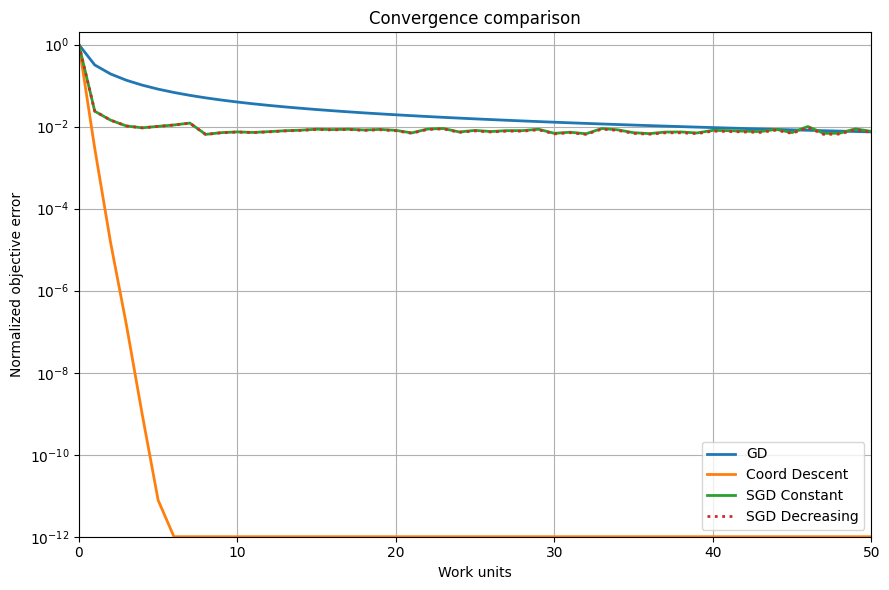

In [69]:

# organize results for easy plotting

results = {
    "GD": (gd_err,gd_t),
    "Coord Descent": (cd_err,cd_t),
    "SGD Constant": (const_ave,const_ave_t),
    "SGD Decreasing": (decr_ave,decr_ave_t)

}

plt.figure(figsize=(9,6))

work = np.arange(51)

for method, (error, method_time) in results.items():
  plot_err = np.maximum(error,1e-12)

  if method == "SGD Decreasing":
    plt.semilogy(
        work,
        plot_err,
        linewidth=2,
        label=method,
        linestyle = 'dotted'
    )
  else:
    plt.semilogy(
        work,
        plot_err,
        linewidth=2,
        label=method
    )
plt.xlabel("Work units")
plt.ylabel("Normalized objective error")
plt.title("Convergence comparison")
plt.grid(True)
plt.legend()
plt.xlim(0,50)
plt.ylim(1e-12,2)

plt.tight_layout()
plt.show()

This completes part (c). It remains to tabulate the first work unit reaching the target for each method, and analyze our results.

In [72]:
# Define a function to find the index at which a method first reaches the target

def first_index(error, target):
  indices = np.where(error<=target)[0]

  if len(indices) == 0:
    return '""'
  return int(indices[0])


# Print the table of indices reaching target values

print("\n First work unit reaching target value")
print('""'*75)

print(
    f"{'Method':<25}"
    f"{'1e-2':>12}"
    f"{'1e-4':>12}"
    f"{'Time (s)':>15}"
)
print('""'*75)
for method, (error, method_time) in results.items():
  t1 = first_index(error,1e-2)
  t2 = first_index(error,1e-4)

  print(
      f"{method: <25}"
      f"{str(t1):>12}"
      f"{str(t2):>12}"
      f"{method_time:>15.6f}"
  )
print('""' * 75)



 First work unit reaching target value
""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""
Method                           1e-2        1e-4       Time (s)
""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""
GD                                 39          ""       0.002998
Coord Descent                       1           2       0.037142
SGD Constant                        4          ""       0.604714
SGD Decreasing                      4          ""       0.609438
""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""


Finally, we compute $\frac{1}{n}\sum_{i=0}^n||g_i(x^*)||^2$

In [76]:
variance = np.mean(1/n*np.sum(((a@x_star-b)[:,None]*a+gamma*x_star)**2,axis=1))
print(variance)

5.335684201776109e-05
